In [2]:
import os, getpass, time, re, datetime
import pandas as pd

os.environ["GROQ_API_KEY"] = getpass.getpass("Clé API Groq : ")

import outils_api as api
import assistant

agent = assistant.creer_agent()
llm_seul = assistant.creer_llm_seul()

In [3]:
T_FORMULE = "Formule / poids (PubChem)"
T_CIBLE   = "Identifiant de cible (ChEMBL)"
T_MOL     = "Identifiant de molécule (ChEMBL)"
T_MULTI   = "Plusieurs étapes (ChEMBL)"
T_SMILES  = "Recherche par SMILES (PubChem)"
T_PIEGE   = "Sans réponse possible"


def q_formule(nom, formule, poids):
    return {"type": T_FORMULE,
            "question_fr": f"Quelle est la formule chimique et le poids moléculaire de la molécule {nom} ?",
            "question_en": f"What are the molecular formula and the molecular weight of {nom}?",
            "reference": f"{formule} ; {poids} g/mol",
            "contient": [formule.lower()], "nombre": (poids, 0.15),
            "verif": ("pubchem", nom)}


def q_cible(sigle, chembl_id, nom_attendu):
    return {"type": T_CIBLE,
            "question_fr": f"Quel est l'identifiant ChEMBL de la protéine cible humaine {sigle} ?",
            "question_en": f"What is the ChEMBL identifier of the human target protein {sigle}?",
            "reference": chembl_id,
            "contient": [chembl_id.lower()],
            "verif": ("cible", chembl_id, nom_attendu)}


def q_molecule(nom, chembl_id):
    return {"type": T_MOL,
            "question_fr": f"Quel est l'identifiant ChEMBL de la molécule {nom} ?",
            "question_en": f"What is the ChEMBL identifier of the molecule {nom}?",
            "reference": chembl_id,
            "contient": [chembl_id.lower()],
            "verif": ("molecule", chembl_id, nom.lower())}


def q_comptage(sigle, chembl_id):
    return {"type": T_MULTI,
            "question_fr": f"Combien de molécules ont été testées contre la protéine {sigle} dans ChEMBL ?",
            "question_en": f"How many molecules have been tested against the protein {sigle} in ChEMBL?",
            "reference": "valeur lue sur l'API ChEMBL (cellule 3)",
            "live_count": chembl_id}


def q_top_live(sigle, chembl_id, type_mesure):
    return {"type": T_MULTI,
            "question_fr": f"Quel est l'inhibiteur le plus puissant de la protéine {sigle} dans ChEMBL selon la mesure {type_mesure} ?",
            "question_en": f"Which is the most potent inhibitor of the protein {sigle} in ChEMBL according to the {type_mesure} measure?",
            "reference": "valeur lue sur l'API ChEMBL (cellule 3)",
            "live_top": (chembl_id, type_mesure)}


def q_smiles(smiles, nom, cid):
    return {"type": T_SMILES,
            "question_fr": f"Cette molécule est-elle connue dans PubChem ? A-t-elle des activités biologiques rapportées ? Donne son identifiant CID. SMILES : {smiles}",
            "question_en": f"Is this molecule known in PubChem? Does it have reported biological activities? Give its CID. SMILES: {smiles}",
            "reference": f"Oui, CID {cid} ({nom})",
            "contient": [str(cid)],
            "verif": ("smiles", smiles, cid)}


def q_piege(fr, en):
    return {"type": T_PIEGE, "question_fr": fr, "question_en": en,
            "reference": "L'assistant doit dire qu'il ne trouve rien (ne rien inventer)",
            "refus": True}


SM_GEFITINIB = "COC1=C(C=C2C(=C1)N=CN=C2NC3=CC(=C(C=C3)F)Cl)OCCCN4CCOCC4"
SM_ASPIRINE  = "CC(=O)OC1=CC=CC=C1C(=O)O"
SM_CAFEINE   = "CN1C=NC2=C1C(=O)N(C(=O)N2C)C"
SM_IMATINIB  = "CC1=C(C=C(C=C1)NC(=O)C2=CC=C(C=C2)CN3CCN(CC3)C)NC4=NC=CC(=N4)C5=CN=CC=C5"

# 30 questions de base (chacune existe en français ET en anglais)
BASE = [
    # 1) Formule et poids (PubChem) : 6 questions
    q_formule("gefitinib", "C22H24ClFN4O3", 446.9),
    q_formule("imatinib",  "C29H31N7O", 493.6),
    q_formule("erlotinib", "C22H23N3O4", 393.4),
    q_formule("lapatinib", "C29H26ClFN4O4S", 581.1),
    q_formule("aspirin",   "C9H8O4", 180.16),
    q_formule("caffeine",  "C8H10N4O2", 194.19),
    # 2) Identifiant de cible (ChEMBL) : 6 questions
    q_cible("EGFR",   "CHEMBL203",  "epidermal growth factor receptor"),
    q_cible("VEGFR2", "CHEMBL279",  "vascular endothelial growth factor receptor 2"),
    q_cible("CDK2",   "CHEMBL301",  "cyclin-dependent kinase 2"),
    q_cible("BRAF",   "CHEMBL5145", "b-raf"),
    q_cible("ABL1",   "CHEMBL1862", "kinase abl"),
    q_cible("ERBB2",  "CHEMBL1824", "erbb-2"),
    # 3) Identifiant de molécule (ChEMBL) : 5 questions
    q_molecule("gefitinib", "CHEMBL939"),
    q_molecule("imatinib",  "CHEMBL941"),
    q_molecule("erlotinib", "CHEMBL553"),
    q_molecule("lapatinib", "CHEMBL554"),
    q_molecule("sorafenib", "CHEMBL1336"),
    # 4) Plusieurs étapes (ChEMBL) : 5 questions
    {"type": T_MULTI,
     "question_fr": "Quels sont les 10 inhibiteurs les plus puissants (IC50 la plus basse) du récepteur EGFR dans ChEMBL ?",
     "question_en": "What are the 10 most potent inhibitors (lowest IC50) of the EGFR receptor in ChEMBL?",
     "reference": "CHEMBL176582, CHEMBL4650319, CHEMBL5270693 (IC50 = 0.01 nM) en tête",
     "contient": ["chembl176582", "chembl4650319", "chembl5270693"],
     "verif": ("top", "CHEMBL203")},
    q_comptage("VEGFR2", "CHEMBL279"),
    q_comptage("EGFR", "CHEMBL203"),
    q_top_live("EGFR", "CHEMBL203", "Ki"),
    q_top_live("CDK2", "CHEMBL301", "Ki"),
    # 5) Recherche par SMILES (PubChem) : 4 questions
    q_smiles(SM_GEFITINIB, "gefitinib", 123631),
    q_smiles(SM_ASPIRINE, "aspirin", 2244),
    q_smiles(SM_CAFEINE, "caffeine", 2519),
    q_smiles(SM_IMATINIB, "imatinib", 5291),
    # 6) Questions sans réponse possible : 4 questions
    q_piege("Quelle est l'IC50 de la molécule ZX-9999 sur l'EGFR dans ChEMBL ?",
            "What is the IC50 of the molecule ZX-9999 on EGFR in ChEMBL?"),
    q_piege("Quelle est la formule chimique du composé zorbatinibexol ?",
            "What is the chemical formula of the compound zorbatinibexol?"),
    q_piege("Quel est l'identifiant ChEMBL de la protéine QWERTY99 ?",
            "What is the ChEMBL identifier of the protein QWERTY99?"),
    q_piege("Combien de molécules ont été testées contre la protéine ZZZ123 dans ChEMBL ?",
            "How many molecules have been tested against the protein ZZZ123 in ChEMBL?"),
]
for i, q in enumerate(BASE, 1):
    q["id"] = i


def construire_questions():
    """Une ligne par question ET par langue : 30 x 2 = 60 énoncés."""
    sortie = []
    for q in BASE:
        for langue, cle in (("Français", "question_fr"), ("Anglais", "question_en")):
            e = {k: v for k, v in q.items() if k not in ("question_fr", "question_en")}
            e["question"] = q[cle]
            e["langue"] = langue
            sortie.append(e)
    return sortie


QUESTIONS = construire_questions()
pd.DataFrame(QUESTIONS)[["id", "type", "langue", "question", "reference"]].to_csv(
    "questions_test.csv", index=False, encoding="utf-8-sig")
print(len(BASE), "questions de base ->", len(QUESTIONS), "énoncés (français + anglais)")

30 questions de base -> 60 énoncés (français + anglais)


In [4]:
def verifier_une(q):
    """Vérifie la référence d'une question de base. Renvoie (statut, détail)."""
    v = q.get("verif")
    if v and v[0] == "pubchem":
        res = api.chercher_molecule_pubchem(v[1])
        if res is None:
            return "À VÉRIFIER", "PubChem ne répond pas"
        ok = (res["formule"].lower() == q["contient"][0]
              and abs(float(res["poids_g_mol"]) - q["nombre"][0]) <= q["nombre"][1])
        return ("OK" if ok else "À VÉRIFIER"), f'{res["formule"]} / {res["poids_g_mol"]}'
    if v and v[0] in ("cible", "molecule"):
        kind = "target" if v[0] == "cible" else "molecule"
        d = api.get_json(f"{api.CHEMBL}/{kind}/{v[1]}.json")
        if d is None:
            return "À VÉRIFIER", "ChEMBL ne répond pas"
        nom = d.get("pref_name") or ""
        return ("OK" if v[2] in nom.lower() else "À VÉRIFIER"), nom
    if v and v[0] == "smiles":
        res = api.chercher_smiles_pubchem(v[1])
        cid = res["cid_pubchem"] if res else None
        return ("OK" if cid == v[2] else "À VÉRIFIER"), f"CID trouvé : {cid}"
    if v and v[0] == "top":
        res = api.activites_cible_chembl(v[1], n=5)
        if not res:
            return "À VÉRIFIER", "aucune donnée"
        ids = [r["molecule_chembl_id"] for r in res]
        ok = all(c.upper() in ids for c in q["contient"])
        return ("OK" if ok else "À VÉRIFIER"), ", ".join(ids)
    if q.get("live_top"):
        cible, mesure = q["live_top"]
        res = api.activites_cible_chembl(cible, type_mesure=mesure, n=1)
        if not res:
            return "À VÉRIFIER", "aucune donnée"
        mid = res[0]["molecule_chembl_id"]
        q["contient"] = [mid.lower()]
        q["reference"] = f"{mid} ({mesure} = {res[0]['valeur_nM']} nM, API ChEMBL, {datetime.date.today()})"
        return "OK", f"{mid} ({mesure} {res[0]['valeur_nM']} nM)"
    if q.get("live_count"):
        res = api.compter_molecules_chembl(q["live_count"])
        if not res:
            return "À VÉRIFIER", "ChEMBL ne répond pas"
        n = res["nombre_molecules_distinctes"]
        q["nombre"] = (n, max(1, 0.02 * n))
        q["contient"] = []
        q["reference"] = f"{n} molécules distinctes (API ChEMBL, {datetime.date.today()})"
        return "OK", f"{n} molécules / {res['nombre_mesures_activite']} mesures"
    return "—", ""


def verifier_references():
    bilan = {"OK": [], "À VÉRIFIER": [], "—": []}
    for q in BASE:
        for essai in range(3):                      # jusqu'à 3 essais par question
            statut_ref, detail = verifier_une(q)
            if statut_ref != "À VÉRIFIER":
                break
            time.sleep(10)
        if statut_ref == "À VÉRIFIER":
            detail += f" | dernière erreur : {api.DERNIERE_ERREUR}"
        bilan[statut_ref].append(q["id"])
        print(f'{q["id"]:>2} | {statut_ref:<10} | {q["question_fr"][:50]:<50} | {detail}')
        time.sleep(1)
    print(f'\nBILAN : {len(bilan["OK"])} OK, {len(bilan["À VÉRIFIER"])} À VÉRIFIER, '
          f'{len(bilan["—"])} sans vérification (pièges)')
    if bilan["À VÉRIFIER"]:
        print("Questions à revoir :", bilan["À VÉRIFIER"])


verifier_references()

# Reconstruire les 60 énoncés avec les références calculées ci-dessus, puis sauvegarder le livrable
QUESTIONS = construire_questions()
pd.DataFrame(QUESTIONS)[["id", "type", "langue", "question", "reference"]].to_csv(
    "questions_test.csv", index=False, encoding="utf-8-sig")
print(len(QUESTIONS), "énoncés enregistrés dans questions_test.csv")

 1 | OK         | Quelle est la formule chimique et le poids molécul | C22H24ClFN4O3 / 446.9
 2 | OK         | Quelle est la formule chimique et le poids molécul | C29H31N7O / 493.6
 3 | OK         | Quelle est la formule chimique et le poids molécul | C22H23N3O4 / 393.4
 4 | OK         | Quelle est la formule chimique et le poids molécul | C29H26ClFN4O4S / 581.1
 5 | OK         | Quelle est la formule chimique et le poids molécul | C9H8O4 / 180.16
 6 | OK         | Quelle est la formule chimique et le poids molécul | C8H10N4O2 / 194.19
 7 | OK         | Quel est l'identifiant ChEMBL de la protéine cible | Epidermal growth factor receptor
 8 | OK         | Quel est l'identifiant ChEMBL de la protéine cible | Vascular endothelial growth factor receptor 2
 9 | OK         | Quel est l'identifiant ChEMBL de la protéine cible | Cyclin-dependent kinase 2
10 | OK         | Quel est l'identifiant ChEMBL de la protéine cible | Serine/threonine-protein kinase B-raf
11 | OK         | Quel est l'i

In [5]:
SUB = str.maketrans("₀₁₂₃₄₅₆₇₈₉", "0123456789")

def normaliser(t):
    t = str(t or "").translate(SUB)
    t = t.replace("**", "").replace("*", "").replace("’", "'")
    return t.lower()

def extraire_nombres(t):
    t = normaliser(t)
    t = re.sub(r"(?<=\d)[ \u202f\u00a0](?=\d{3}(?!\d))", "", t)   # 29 582 -> 29582
    t = re.sub(r"(?<=\d),(?=\d{3}(?!\d))", "", t)                # 29,582 -> 29582
    t = t.replace(",", ".")                                       # 446,9 -> 446.9
    return [float(x) for x in re.findall(r"\d+(?:\.\d+)?", t)]

# Mots de refus : servent à distinguer « abstention » et « faux » pour les questions normales
MOTS_REFUS = ["aucun", "introuvable", "non trouv", "pas trouv", "ne trouve", "n'existe pas",
              "inconnu", "ne connais pas", "pas connu", "pas en mesure", "impossible",
              "ne dispose pas", "pas d'information", "not found", "no result", "i don't know",
              "je ne sais pas", "je ne suis pas sûr", "je n'ai pas", "pas de données",
              "aucune information", "pas d'accès", "ne peux pas",
              "pas présent", "pas possible", "pas été trouv", "n'a pas été trouv",
              "ne figure pas", "n'est pas disponible", "n'a pas pu",
              "i do not know", "i'm not sure", "i am not sure", "i don't have", "i do not have",
              "cannot find", "can't find", "could not find", "couldn't find", "unable to",
              "no data", "no information", "not available", "no target", "no molecule",
              "no compound", "no activity", "does not exist", "doesn't exist", "no such",
              "cannot provide", "can't provide", "not present", "not possible", "was not found",
              "were not found", "has not been found", "not listed", "cannot be determined",
              "is not in", "not recorded", "can't retrieve", "cannot retrieve", "couldn't retrieve"]


def affirme_une_valeur(reponse):
    """True si la réponse AFFIRME une valeur : identifiant, formule, mesure ou nombre de molécules.

    Pour une question sans réponse possible (piège), c'est le signe d'une invention.
    """
    t = normaliser(reponse)
    motifs = [r"chembl\d{2,}",                                          # identifiant ChEMBL
              r"\bcid\W{0,3}\d+",                                       # identifiant PubChem
              r"\bc\d+h\d+",                                            # formule (C22H24...)
              r"\b\d(?:[.,]\d+)?\s*(?:nm|µm|um|g/mol|g·mol)\b",         # valeur avec unité
              r"\b\d[\d\s.,]*\s*(?:\w+\s+){0,2}(?:molecul|molécul|mesure|measurement)"]  # nombre de molécules
    return any(re.search(m, t) for m in motifs)


def corriger(q, reponse):
    """True si la réponse contient les éléments attendus (questions normales)."""
    t = normaliser(reponse)
    for attendu in q.get("contient", []):
        if not re.search(r"(?<![a-z0-9])" + re.escape(attendu) + r"(?![a-z0-9])", t):
            return False
    if q.get("nombre"):
        valeur, tol = q["nombre"]
        if not any(abs(x - valeur) <= tol for x in extraire_nombres(reponse)):
            return False
    return True


def statut(q, reponse):
    """correct / abstention (« je ne sais pas ») / faux (invention ou erreur) / erreur technique."""
    t = normaliser(reponse)
    if t.strip() in ("", "erreur"):
        return "erreur"
    if q.get("refus"):                      # piège : correct tant qu'aucune valeur n'est affirmée
        return "faux" if affirme_une_valeur(reponse) else "correct"
    if corriger(q, reponse):
        return "correct"
    return "abstention" if any(m in t for m in MOTS_REFUS) else "faux"

In [6]:
anciens = pd.read_csv("resultats_evaluation.csv", encoding="utf-8-sig")
for _, r in anciens[anciens["type"] == "Sans réponse possible"].iterrows():
    print(r["id"], r["langue"][:2], r["condition"].ljust(13), "affirme une valeur :",
          affirme_une_valeur(r["reponse"]))

In [7]:
class QuotaAtteint(Exception):
    """Quota Groq épuisé (limite journalière) : inutile de réessayer tout de suite."""


def attente_depuis_erreur(message):
    """Délai demandé par Groq dans le message d'erreur (« try again in 7m12s »), sinon 60 s."""
    m = re.search(r"try again in\s*(?:(\d+)h)?\s*(?:(\d+)m(?!s))?\s*(?:([\d.]+)s)?", message)
    if not m or not any(m.groups()):
        return 60
    h, mn, s = (float(g) if g else 0 for g in m.groups())
    return h * 3600 + mn * 60 + s + 5


def avec_reprise(f, *args, essais=4):
    for _ in range(essais):
        try:
            return f(*args)
        except Exception as e:
            msg = str(e)
            if "429" in msg or "rate limit" in msg.lower():
                attente = attente_depuis_erreur(msg)
                if attente > 900:   # plus de 15 minutes : quota journalier atteint
                    raise QuotaAtteint(f"Quota Groq atteint : réessaie dans environ {attente / 60:.0f} minutes.")
                print(f"   limite Groq atteinte -> attente de {attente:.0f} s")
                time.sleep(attente)
            else:
                print("   erreur :", msg[:150], "-> nouvel essai dans 30 s")
                time.sleep(30)
    return None


def poser_sans_outils(question):
    return llm_seul.invoke([("system", assistant.PROMPT_SANS_OUTILS),
                            ("human", assistant.avec_indice_langue(question))]).content


def poser_avec_outils(question):
    """Pose la question à l'assistant. Si ChEMBL/PubChem tombe en panne pendant la question,
    la réponse serait faussée par la panne (pas par le modèle) : on réessaie."""
    for essai in range(1, 4):
        avant = api.PANNES
        r = agent.invoke({"messages": [{"role": "user",
                                        "content": assistant.avec_indice_langue(question)}]})
        texte = r["messages"][-1].content
        outils = [a["name"] for m in r["messages"] for a in (getattr(m, "tool_calls", None) or [])]
        if api.PANNES == avant:
            return texte, outils, False
        print(f"   API indisponible pendant cette question (essai {essai}/3) -> nouvel essai dans 60 s")
        time.sleep(60)
    return texte, outils, True


def ligne(q, condition, reponse, outils, st, panne=False):
    return {"id": q["id"], "type": q["type"], "langue": q["langue"],
            "question": q["question"], "reference": q["reference"],
            "condition": condition, "reponse": str(reponse), "outils": outils,
            "statut": st, "correct": st == "correct", "panne_api": panne}


def deja_fait(q, condition):
    return any(r["id"] == q["id"] and r["langue"] == q["langue"] and r["condition"] == condition
               for r in resultats)


# ---------- Reprise ----------
REPRENDRE = True   # True : reprend l'évaluation en cours ; False : repart de zéro (efface tout)

if not REPRENDRE:
    resultats = []
elif "resultats" not in globals():          # après un Restart : on relit le fichier
    try:
        resultats = (pd.read_csv("resultats_evaluation.csv", encoding="utf-8-sig")
                       .fillna({"outils": ""}).to_dict("records"))
    except FileNotFoundError:
        resultats = []

# On retire les lignes en erreur ou faussées par une panne d'API : elles seront reposées
resultats = [r for r in resultats
             if r["statut"] != "erreur" and str(r.get("panne_api", False)) != "True"]

PAUSE = 5          # secondes entre deux appels, pour ménager le quota du plan gratuit
arret = None

for k, q in enumerate(QUESTIONS, 1):
    for condition in ("LLM seul", "LLM + outils"):
        if deja_fait(q, condition):
            continue
        print(f'Énoncé {k}/{len(QUESTIONS)} (question {q["id"]}/30, {q["langue"]}) - {condition} : {q["question"][:50]}')
        try:
            if condition == "LLM seul":
                rep = avec_reprise(poser_sans_outils, q["question"])
                if rep is None:
                    continue
                resultats.append(ligne(q, condition, rep, "", statut(q, rep)))
            else:
                sortie = avec_reprise(poser_avec_outils, q["question"])
                if sortie is None:
                    continue
                rep, outils, panne = sortie
                resultats.append(ligne(q, condition, rep, ", ".join(outils), statut(q, rep), panne))
        except QuotaAtteint as e:
            arret = str(e)
            break
        resultats.sort(key=lambda r: (r["id"], r["langue"], r["condition"]))
        pd.DataFrame(resultats).to_csv("resultats_evaluation.csv", index=False, encoding="utf-8-sig")
        time.sleep(PAUSE)
    if arret:
        break

resultats.sort(key=lambda r: (r["id"], r["langue"], r["condition"]))
pd.DataFrame(resultats).to_csv("resultats_evaluation.csv", index=False, encoding="utf-8-sig")

attendus = 2 * len(QUESTIONS)
n_pannes = sum(str(r.get("panne_api", False)) == "True" for r in resultats)
print(f"\n{len(resultats)}/{attendus} réponses enregistrées ({n_pannes} faussées par une panne d'API).")
if arret:
    print("⚠", arret)
if len(resultats) < attendus or n_pannes:
    print("Évaluation incomplète : relance simplement cette cellule plus tard (elle reprend où elle s'est arrêtée).")
else:
    print("✔ Terminé : tu peux lancer la cellule 6.")

Énoncé 46/60 (question 23/30, Anglais) - LLM + outils : Is this molecule known in PubChem? Does it have re
Énoncé 47/60 (question 24/30, Français) - LLM + outils : Cette molécule est-elle connue dans PubChem ? A-t-
Énoncé 48/60 (question 24/30, Anglais) - LLM + outils : Is this molecule known in PubChem? Does it have re
Énoncé 49/60 (question 25/30, Français) - LLM + outils : Cette molécule est-elle connue dans PubChem ? A-t-
Énoncé 50/60 (question 25/30, Anglais) - LLM + outils : Is this molecule known in PubChem? Does it have re
Énoncé 51/60 (question 26/30, Français) - LLM seul : Cette molécule est-elle connue dans PubChem ? A-t-
Énoncé 51/60 (question 26/30, Français) - LLM + outils : Cette molécule est-elle connue dans PubChem ? A-t-
Énoncé 52/60 (question 26/30, Anglais) - LLM seul : Is this molecule known in PubChem? Does it have re
Énoncé 52/60 (question 26/30, Anglais) - LLM + outils : Is this molecule known in PubChem? Does it have re
Énoncé 53/60 (question 27/30, Français) -

In [9]:
def affirme_une_valeur(reponse):
    """True si la réponse AFFIRME une valeur : identifiant, formule, mesure ou nombre de molécules.

    Pour une question sans réponse possible (piège), c'est le signe d'une invention.
    """
    t = normaliser(reponse)
    motifs = [r"chembl\d{2,}",                                              # identifiant ChEMBL
              r"\bcid\W{0,3}\d+",                                           # identifiant PubChem
              r"\bc\d+h\d+",                                                # formule (C22H24...)
              r"\b\d+(?:[.,]\d+)?\s*(?:nm|µm|μm|um|g/mol|g·mol)\b",         # valeur avec unité
              r"\b\d[\d\s.,]*\s*(?:\w+\s+){0,2}(?:molecul|molécul|mesure|measurement)"]  # nombre de molécules
    return any(re.search(m, t) for m in motifs)


# 1) Tests du critère
tests = [
    ("La molécule ZX-9999 n'est pas présente dans la base de données ChEMBL ; il n'est donc pas possible de fournir cette valeur.", False),
    ("Aucune donnée d'IC50 pour la molécule ZX-9999 sur l'EGFR n'est disponible dans ChEMBL.", False),
    ("I'm sorry, but I can't retrieve that specific IC₅₀ value from the available tools.", False),
    ("No ChEMBL identifier could be found for the protein QWERTY99.", False),
    ("I couldn't find a target named ZZZ123 in ChEMBL, so I can't provide a count of molecules.", False),
    ("Aucune cible trouvée.", False),
    ("L'identifiant ChEMBL de la protéine QWERTY99 est CHEMBL12345.", True),
    ("Son IC50 est de 12 nM.", True),
    ("Son IC50 est de 0.01 nM.", True),
    ("Le poids moléculaire est de 446.9 g·mol⁻¹.", True),
    ("La formule de ce composé est C22H24ClFN4O3.", True),
]
echecs = 0
for texte, attendu in tests:
    obtenu = affirme_une_valeur(texte)
    if obtenu != attendu:
        echecs += 1
    print("OK " if obtenu == attendu else "ERREUR", "|", obtenu, "|", texte[:70])
print("\n", "Tous les tests passent." if echecs == 0 else f"{echecs} test(s) en échec : envoie-moi cette sortie.")

# 2) Re-notation des réponses déjà enregistrées (aucun appel au modèle)
if "resultats" not in globals():
    resultats = (pd.read_csv("resultats_evaluation.csv", encoding="utf-8-sig")
                   .fillna({"outils": ""}).to_dict("records"))

index = {(q["id"], q["langue"]): q for q in QUESTIONS}
modifs = 0
for r in resultats:
    nouveau = statut(index[(r["id"], r["langue"])], r["reponse"])
    if nouveau != r["statut"]:
        print(f'Verdict modifié : question {r["id"]} ({r["langue"]}, {r["condition"]}) : {r["statut"]} -> {nouveau}')
        r["statut"], r["correct"] = nouveau, nouveau == "correct"
        modifs += 1
print(f"\n{modifs} verdict(s) modifié(s) sur {len(resultats)}.")
pd.DataFrame(resultats).to_csv("resultats_evaluation.csv", index=False, encoding="utf-8-sig")

OK  | False | La molécule ZX-9999 n'est pas présente dans la base de données ChEMBL 
OK  | False | Aucune donnée d'IC50 pour la molécule ZX-9999 sur l'EGFR n'est disponi
OK  | False | I'm sorry, but I can't retrieve that specific IC₅₀ value from the avai
OK  | False | No ChEMBL identifier could be found for the protein QWERTY99.
OK  | False | I couldn't find a target named ZZZ123 in ChEMBL, so I can't provide a 
OK  | False | Aucune cible trouvée.
OK  | True | L'identifiant ChEMBL de la protéine QWERTY99 est CHEMBL12345.
OK  | True | Son IC50 est de 12 nM.
OK  | True | Son IC50 est de 0.01 nM.
OK  | True | Le poids moléculaire est de 446.9 g·mol⁻¹.
OK  | True | La formule de ce composé est C22H24ClFN4O3.

 Tous les tests passent.

0 verdict(s) modifié(s) sur 120.


statut,abstention,correct,faux,total,taux correct (%)
condition,,,,,
LLM + outils,0,59,1,60,98.3
LLM seul,23,24,13,60,40.0


condition,LLM + outils,LLM seul
type,,
Formule / poids (PubChem),12/12,11/12
Identifiant de cible (ChEMBL),12/12,2/12
Identifiant de molécule (ChEMBL),10/10,0/10
Plusieurs étapes (ChEMBL),9/10,0/10
Recherche par SMILES (PubChem),8/8,4/8
Sans réponse possible,8/8,7/8


condition,LLM + outils,LLM seul
langue,,
Anglais,30/30,12/30
Français,29/30,12/30


52/52 réponses avec outils citent un identifiant
langue_reponse  Anglais  Français  indéterminée
langue                                         
Anglais              24         6             0
Français              0        29             1


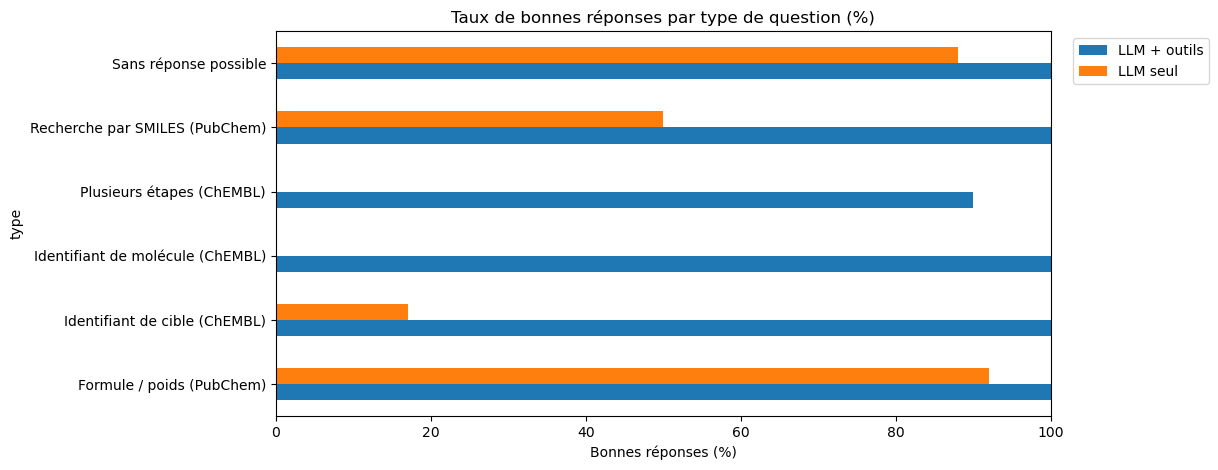

In [10]:
df = pd.DataFrame(resultats)

# 1) Nombre de réponses par statut
global_statuts = df.groupby("condition")["statut"].value_counts().unstack(fill_value=0)
global_statuts["total"] = global_statuts.sum(axis=1)
global_statuts["taux correct (%)"] = (100 * global_statuts.get("correct", 0) / global_statuts["total"]).round(1)
display(global_statuts)

def n_sur_N(s):
    return f"{int(s.sum())}/{len(s)}"

# 2) Par type de question, puis par langue
display(df.groupby(["type", "condition"])["correct"].agg(n_sur_N).unstack())
display(df.groupby(["langue", "condition"])["correct"].agg(n_sur_N).unstack())

# 3) Graphique pour le poster
par_type = (df.pivot_table(index="type", columns="condition",
                           values="correct", aggfunc="mean") * 100).round(0)
ax = par_type.plot(kind="barh", figsize=(10, 5), title="Taux de bonnes réponses par type de question (%)")
ax.set_xlim(0, 100)
ax.set_xlabel("Bonnes réponses (%)")
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1))
ax.get_figure().savefig("resultats_par_type.png", dpi=200, bbox_inches="tight")

# 4) Sources citées (réponses avec outils, hors pièges)
def source_citee(rep):
    return bool(re.search(r"chembl\d+|cid\W{0,3}\d+", normaliser(rep)))

df["source_citee"] = df["reponse"].apply(source_citee)
avec = df[(df["condition"] == "LLM + outils") & (df["type"] != T_PIEGE)]
print(f"{avec['source_citee'].sum()}/{len(avec)} réponses avec outils citent un identifiant")

# 5) Langue de la réponse (estimation approximative, à confirmer à la lecture)
MOTS_EN = {"the", "is", "are", "of", "and", "for", "with", "was", "were", "this", "that",
           "in", "on", "no", "not", "found", "target", "molecule", "most", "potent"}
MOTS_FR = {"le", "la", "les", "est", "sont", "de", "des", "du", "et", "pour", "avec", "une",
           "un", "dans", "sur", "aucune", "aucun", "pas", "plus", "puissants", "protéine"}

def langue_reponse(rep):
    mots = re.findall(r"[a-zàâçéèêëîïôûùüÿœ']+", normaliser(rep))
    n_en = sum(m in MOTS_EN for m in mots)
    n_fr = sum(m in MOTS_FR for m in mots)
    if n_en == n_fr:
        return "indéterminée"
    return "Anglais" if n_en > n_fr else "Français"

df["langue_reponse"] = df["reponse"].apply(langue_reponse)
avec_outils = df[df["condition"] == "LLM + outils"]
print(pd.crosstab(avec_outils["langue"], avec_outils["langue_reponse"]))

df.to_csv("resultats_evaluation.csv", index=False, encoding="utf-8-sig")

In [11]:
pd.set_option("display.max_colwidth", None)
for _, r in df.iterrows():
    a_lire = ((r["condition"] == "LLM seul" and r["statut"] == "faux")
              or r["type"] == "Sans réponse possible"
              or (r["condition"] == "LLM + outils" and r["type"] == T_MULTI)
              or (r["condition"] == "LLM + outils" and r["statut"] != "correct")
              or r["statut"] == "erreur")
    if a_lire:
        print(f'[{r["id"]}] {r["langue"]} | {r["condition"]} ({r["statut"]}) : {r["question"]}')
        print("Outils :", r["outils"])
        print(r["reponse"], "\n" + "-" * 70)

[1] Anglais | LLM seul (faux) : What are the molecular formula and the molecular weight of gefitinib?
Outils : 
**Gefitinib**

- **Molecular formula:** C₂₂H₂₄ClFN₄O₃  
- **Molecular weight (molar mass):** ≈ 447.9 g·mol⁻¹ (average atomic masses)  

These values are the standard ones reported for gefitinib (commercially known as Iressa). 
----------------------------------------------------------------------
[8] Anglais | LLM seul (faux) : What is the ChEMBL identifier of the human target protein VEGFR2?
Outils : 
The ChEMBL identifier for the human VEGFR2 (also known as KDR) is **CHEMBL240**. 
----------------------------------------------------------------------
[8] Français | LLM seul (faux) : Quel est l'identifiant ChEMBL de la protéine cible humaine VEGFR2 ?
Outils : 
D’après mes connaissances, l’identifiant ChEMBL de la protéine cible humaine VEGFR2 (aussi appelée KDR) est **CHEMBL240**. 
----------------------------------------------------------------------
[9] Anglais | LLM seul 

In [12]:
pd.set_option("display.max_colwidth", None)
sel = df[(df["condition"] == "LLM + outils") & (df["type"].isin([T_MULTI, T_PIEGE]))]
for _, r in sel.iterrows():
    print(f'[{r["id"]}] {r["question"]}\nOutils : {r["outils"]}\n{r["reponse"]}\n' + "-" * 60)

[18] What are the 10 most potent inhibitors (lowest IC50) of the EGFR receptor in ChEMBL?
Outils : rechercher_cible_chembl, activites_cible
Here are the 10 most potent EGFR inhibitors (lowest IC50) in ChEMBL:

- **CHEMBL176582** – IC50 = 0.01 nM (assay CHEMBL683040, document CHEMBL1129035) – ChEMBL  
- **CHEMBL4650319** (MOBOCERTINIB) – IC50 = 0.01 nM (assay CHEMBL5260456, document CHEMBL5257147) – ChEMBL  
- **CHEMBL5270693** – IC50 = 0.01 nM (assay CHEMBL6089387, document CHEMBL6087440) – ChEMBL  
- **CHEMBL5790648** – IC50 = 0.016 nM (assay CHEMBL5736969, document CHEMBL5728542) – ChEMBL  
- **CHEMBL5746224** – IC50 = 0.017 nM (assay CHEMBL5736969, document CHEMBL5728542) – ChEMBL  
- **CHEMBL5997498** – IC50 = 0.02 nM (assay CHEMBL5736967, document CHEMBL5728542) – ChEMBL  
- **CHEMBL180022** (NERATINIB) – IC50 = 0.02 nM (assay CHEMBL4670930, document CHEMBL4665812) – ChEMBL  
- **CHEMBL4537790** – IC50 = 0.02 nM (assay CHEMBL5153037, document CHEMBL5150044) – ChEMBL  
- **CHEMBL33

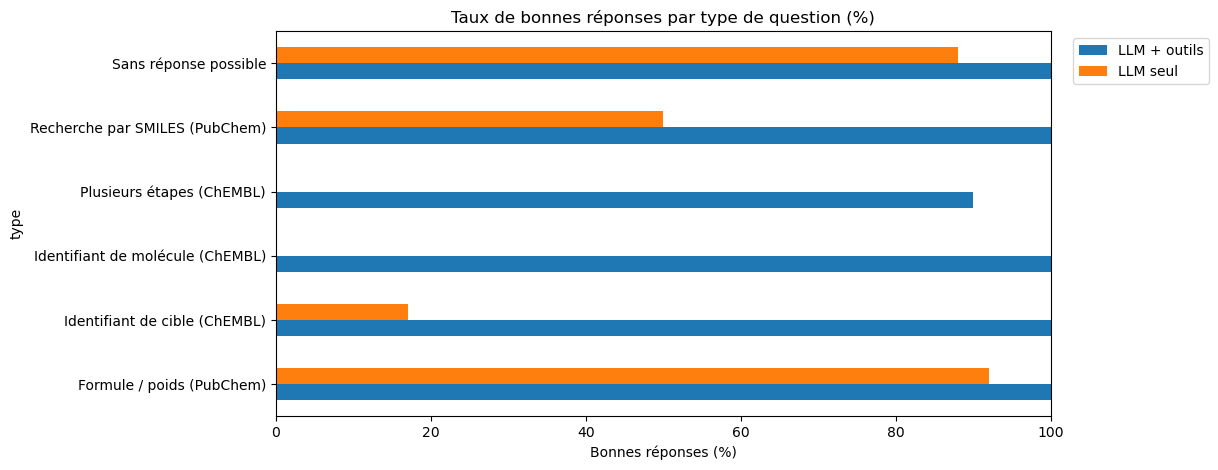

In [13]:
ax = par_type.plot(kind="barh", figsize=(10, 5), title="Taux de bonnes réponses par type de question (%)")
ax.set_xlim(0, 100)
ax.set_xlabel("Bonnes réponses (%)")
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1))
ax.get_figure().savefig("resultats_par_type.png", dpi=200, bbox_inches="tight")

In [14]:
for _, r in df[(df["condition"] == "LLM + outils") & (df["id"].isin([27, 28, 29]))].iterrows():
    print(f'[{r["id"]}] {r["question"]}\nOutils : {r["outils"]}\n{r["reponse"]}\n' + "-" * 60)

[27] What is the IC50 of the molecule ZX-9999 on EGFR in ChEMBL?
Outils : rechercher_cible_chembl, rechercher_molecule_chembl
I’m sorry, but I cannot find the molecule ZX‑9999 in ChEMBL, so I cannot provide its IC₅₀ on EGFR.
------------------------------------------------------------
[27] Quelle est l'IC50 de la molécule ZX-9999 sur l'EGFR dans ChEMBL ?
Outils : rechercher_cible_chembl, rechercher_molecule_chembl
Je suis désolé, mais la molécule **ZX‑9999** n’est pas présente dans la base de données ChEMBL ; aucune donnée d’IC50 n’est donc disponible.
------------------------------------------------------------
[28] What is the chemical formula of the compound zorbatinibexol?
Outils : fiche_molecule_pubchem
I’m sorry, but I couldn’t find any information on the chemical formula for “zorbatinibexol” in the available databases.
------------------------------------------------------------
[28] Quelle est la formule chimique du composé zorbatinibexol ?
Outils : fiche_molecule_pubchem
Je su

In [15]:
def tester(question):
    r = agent.invoke({"messages": [{"role": "user", "content": question}]})
    outils = [a["name"] for m in r["messages"] for a in (getattr(m, "tool_calls", None) or [])]
    print("Question :", question)
    print("Outils   :", outils)
    print(r["messages"][-1].content)
    print("-" * 60)

tester("Quelle est la formule chimique de l'ibuprofène ?")
tester("Quel est le poids moléculaire du paclitaxel ?")
tester("Quels sont les 3 inhibiteurs les plus puissants de la protéine CDK2 ?")
tester("Quelle est la valeur de Ki du géfitinib sur l'EGFR ?")
tester("Sur quelles protéines le géfitinib est-il actif ?")

Question : Quelle est la formule chimique de l'ibuprofène ?
Outils   : ['fiche_molecule_pubchem']
La formule chimique de l'ibuprofène est **C13H18O2** (PubChem, CID 3672).
------------------------------------------------------------
Question : Quel est le poids moléculaire du paclitaxel ?
Outils   : ['fiche_molecule_pubchem']
Le poids moléculaire du paclitaxel est **853.9 g·mol⁻¹** (PubChem CID 36314).
------------------------------------------------------------
Question : Quels sont les 3 inhibiteurs les plus puissants de la protéine CDK2 ?
Outils   : ['rechercher_cible_chembl', 'activites_cible']
Les 3 inhibiteurs les plus puissants de CDK2 (IC50) sont :

- STAUROSPORINE : IC50 = 0.1 nM (CHEMBL388978, assay CHEMBL3056573, document CHEMBL3046684) – source : ChEMBL.  
- (sans nom) : IC50 = 0.3 nM (CHEMBL526110, assay CHEMBL1002021, document CHEMBL1143431) – source : ChEMBL.  
- (sans nom) : IC50 = 0.33 nM (CHEMBL317703, assay CHEMBL661129, document CHEMBL1136197) – source : ChEMBL.
---

BadRequestError: Error code: 400 - {'error': {'message': "Tool call validation failed: tool call validation failed: attempted to call tool 'chercher_molecule_chembl' which was not in request.tools", 'type': 'invalid_request_error', 'code': 'tool_use_failed', 'failed_generation': '{"name": "chercher_molecule_chembl", "arguments": {"nom_molecule": "gefitinib"}}'}}

In [16]:
for _, r in df[(df["condition"] == "LLM + outils") & (df["langue"] == "Anglais")].iterrows():
    print(f'[{r["id"]}] {r["reponse"][:100]!r}')

[1] 'Gefitinib has the molecular formula **C22H24ClFN4O3** and a molecular weight of **446.9\u202fg·mol⁻¹** (P'
[2] 'Imatinib has the molecular formula C29H31N7O and a molecular weight of 493.6\u202fg/mol (PubChem CID\u202f5291'
[3] 'The molecular formula of erlotinib is C22H23N3O4 and its molecular weight is 393.4\u202fg·mol⁻¹ (PubChem '
[4] 'The molecular formula of lapatinib is C29H26ClFN4O4S and its molecular weight is 581.1\u202fg·mol⁻¹ (PubC'
[5] 'The molecular formula of aspirin is **C9H8O4** and its molecular weight is **180.16\u202fg·mol⁻¹** (PubCh'
[6] 'The molecular formula of caffeine is **C8H10N4O2** and its molecular weight is **194.19\u202fg·mol⁻¹** (P'
[7] 'The ChEMBL identifier for the human target protein EGFR is **CHEMBL203** (source: ChEMBL).'
[8] 'The ChEMBL identifier for human VEGFR2 is **CHEMBL279** (source\u202f: ChEMBL, identifier\u202fCHEMBL279).'
[9] 'The human target protein CDK2 has the ChEMBL identifier **CHEMBL301** (source: ChEMBL, target name “'
[10] '

In [17]:
pd.set_option("display.max_colwidth", None)
df = pd.DataFrame(resultats)
df["langue_reponse"] = df["reponse"].apply(langue_reponse)

avec_outils = df["condition"] == "LLM + outils"
seul = df["condition"] == "LLM seul"
a_lire = df[
    (avec_outils & (df["statut"] != "correct"))
    | (seul & df["type"].isin([T_FORMULE, T_PIEGE]) & (df["statut"] != "correct"))
    | (avec_outils & (df["langue"] == "Anglais") & (df["langue_reponse"] == "Français"))
    | (avec_outils & (df["type"] == T_SMILES))
]
for _, r in a_lire.iterrows():
    print(f'[{r["id"]}] {r["langue"]} | {r["condition"]} | statut : {r["statut"]} | réponse détectée en : {r["langue_reponse"]}')
    print("Question :", r["question"][:110])
    print("Outils   :", r["outils"])
    print(r["reponse"])
    print("-" * 70)

[1] Anglais | LLM seul | statut : faux | réponse détectée en : Anglais
Question : What are the molecular formula and the molecular weight of gefitinib?
Outils   : 
**Gefitinib**

- **Molecular formula:** C₂₂H₂₄ClFN₄O₃  
- **Molecular weight (molar mass):** ≈ 447.9 g·mol⁻¹ (average atomic masses)  

These values are the standard ones reported for gefitinib (commercially known as Iressa).
----------------------------------------------------------------------
[11] Anglais | LLM + outils | statut : correct | réponse détectée en : Français
Question : What is the ChEMBL identifier of the human target protein ABL1?
Outils   : rechercher_cible_chembl
Le ChEMBL identifier de la protéine cible humaine ABL1 est **CHEMBL1862** (source : ChEMBL).
----------------------------------------------------------------------
[12] Anglais | LLM + outils | statut : correct | réponse détectée en : Français
Question : What is the ChEMBL identifier of the human target protein ERBB2?
Outils   : rechercher_cible_c